# 06 黑马优购 - uni-app 起步、tabBar 与首页


本篇是微信小程序**项目第 1 天**，对应“黑马优购”商城的起步、tabBar 和首页开发。按原课顺序完成：搭建 uni-app 开发环境 → 创建项目并运行到微信开发者工具 → 配置四个 tabBar 页面 → 封装网络请求 → 渲染轮播图、分类导航和商品楼层。

本项目使用 Vue 2 风格的 uni-app 单文件组件：在 `.vue` 文件中组合模板、逻辑和 SCSS 样式，再编译成微信小程序。学习本篇前，需要掌握前面基础笔记中的数据绑定、事件、请求、导航和分包，并能阅读 Vue 的 `data`、`methods`、`v-for` 与 `:属性`。

本篇依据[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)的“微信小程序项目/微信小程序项目-资料/day01.rar”整理。本机对应文件是 `D:\baidudisk\BaiduNetdiskDownload\day01(1).rar`，区别于基础第 1 天的 `day01.rar`。已读取包内 `学习目标.txt`、17 页 `讲义（pdf）/uni-shop.pdf`、`讲义（md）/微信小程序商城API文档.md`，并核对 `代码/uni-shop-2` 的完成版源码。教学图片取自同课程在线讲义的[起步](https://applet-base-api-t.itheima.net/docs-uni-shop/1.start.html)、[tabBar](https://applet-base-api-t.itheima.net/docs-uni-shop/2.tabbar.html)、[首页](https://applet-base-api-t.itheima.net/docs-uni-shop/3.home.html)，内嵌在本笔记中。

包内学习目标对应本篇五项操作：配置 uni-app 开发环境、运行到微信开发者工具、配置 tabBar、配置分包并创建页面、发起网络数据请求。讲义按“1. 起步 → 2. tabBar → 3. 首页”展开，首页依次实现轮播图、分类导航与楼层区域。

| 文件或目录 | 本篇用途 |
| --- | --- |
| `manifest.json` | 填写微信小程序 AppID，配置运行平台 |
| `pages.json` | 页面注册、导航栏、tabBar 与 `subPackages` |
| `main.js` | 挂载 `uni.$http`，配置拦截器和 `uni.$showMsg()` |
| `pages/home/home.vue` | 首页轮播、导航、楼层及点击跳转 |
| `pages/cate`、`pages/cart`、`pages/my` | 主包 tabBar 页面，本天先创建基本页面 |
| `subpkg/goods_detail`、`subpkg/goods_list` | 分包中的跳转目标，本天先创建页面占位 |
| `static/tab_icons` | tabBar 未选中与选中图标 |

下文代码合并到标明的文件中，保留其他已有配置。Git 和 npm 命令均在课程项目根目录执行；笔记只展示命令与代码，不实际执行项目开发、安装或推送操作。


## 一、起步：理解 uni-app 与开发工具

### 1. 一套 Vue 代码，编译到不同平台

uni-app 是使用 Vue.js 开发前端应用的框架。开发者编写一套代码，通过编译与平台适配，发布到 iOS、Android、H5、微信及其他小程序、快应用等平台。本课将运行目标设为**微信小程序**。

原课用下图说明“编写 → 编译/转换 → 多平台”的过程。编写时使用 uni-app 的组件和 `uni` API；运行到微信开发者工具时，看到的是编译后的小程序。

官方文档：[uni-app](https://uniapp.dcloud.net.cn/)。

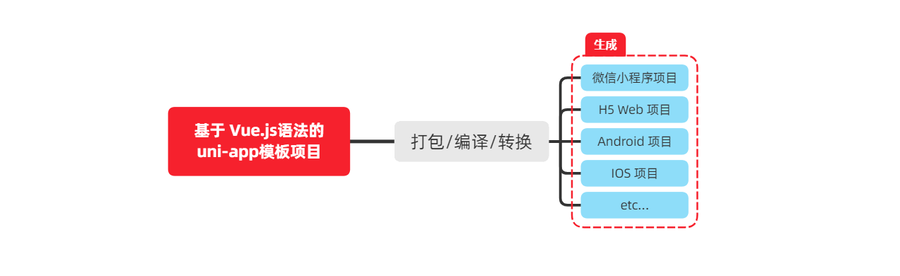


### 2. 下载、解压并启动 HBuilderX

原课推荐 HBuilderX，因为它提供项目模板、智能提示和一键运行，也说明可以使用自己熟悉的编辑器。后续操作按 HBuilderX 的界面展开。

1. 进入 [HBuilderX 官方下载页](https://www.dcloud.io/hbuilderx.html)，点击 `DOWNLOAD`。
2. 按课程选择“正式版 → App 开发版”。
3. 解压下载的 ZIP，将目录放到**纯英文路径**，避免括号等特殊字符。
4. 双击解压目录中的 `HBuilderX.exe` 启动。

课件使用 HBuilderX 2.7.14；截图中的菜单名称和位置属于课程版本，当前软件界面可能有所调整。本篇仍使用配套的 Vue 2 写法。


### 3. 安装 SCSS 编译插件与调整编辑器

本项目使用 `<style lang="scss">` 编写嵌套样式。先在[原课 SCSS/SASS 编译插件页](https://ext.dcloud.net.cn/plugin?name=compile-node-sass)点击“使用 HBuilderX 导入插件”，按提示完成安装。

课件中的插件导入入口如下：

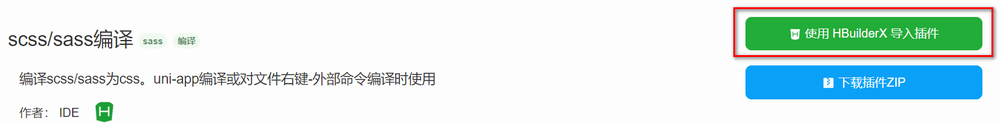


需要沿用 VS Code 快捷键时，进入“工具 → 预设快捷键方案切换 → VS Code”：

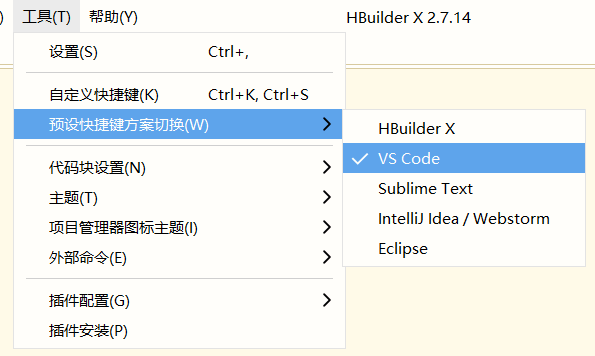


编辑器设置在“工具 → 设置 → 打开 Settings.json”中修改。先进入设置，再选择左侧“源码视图”，原课参考配置如下：

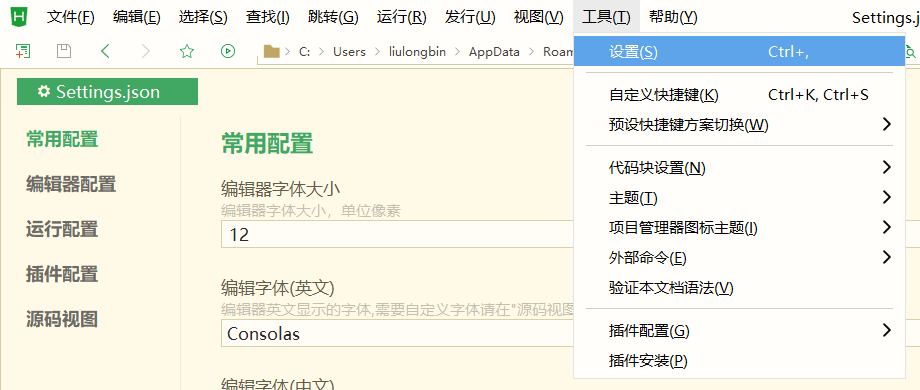


```json
{
  "editor.colorScheme": "Default",
  "editor.fontSize": 12,
  "editor.fontFamily": "Consolas",
  "editor.fontFmyCHS": "微软雅黑 Light",
  "editor.insertSpaces": true,
  "editor.lineHeight": "1.5",
  "editor.minimap.enabled": false,
  "editor.mouseWheelZoom": true,
  "editor.onlyHighlightWord": false,
  "editor.tabSize": 2,
  "editor.wordWrap": true,
  "explorer.iconTheme": "vs-seti",
  "editor.codeassist.px2rem.enabel": false,
  "editor.codeassist.px2upx.enabel": false
}
```

其中 `editor.tabSize: 2` 与 `editor.insertSpaces: true` 用于两空格缩进；`editor.wordWrap` 控制自动换行，`editor.mouseWheelZoom` 允许按住 Ctrl 用滚轮缩放。配置键名按原讲义保留，包括两项 `enabel`；它们属于 HBuilderX 设置，不能直接当作 VS Code 设置使用。


## 二、创建项目与认识目录

### 1. 新建 uni-app 项目

1. 在 HBuilderX 中选择“文件 → 新建 → 项目”。
2. 选择 `uni-app` 类型，填写项目名称与保存目录。
3. 选择默认模板；原课截图为“默认模板（Vue 2）”。
4. 点击“创建”，确认左侧出现项目目录。

截图中的项目名和路径是教师示例，换成自己的项目目录即可。

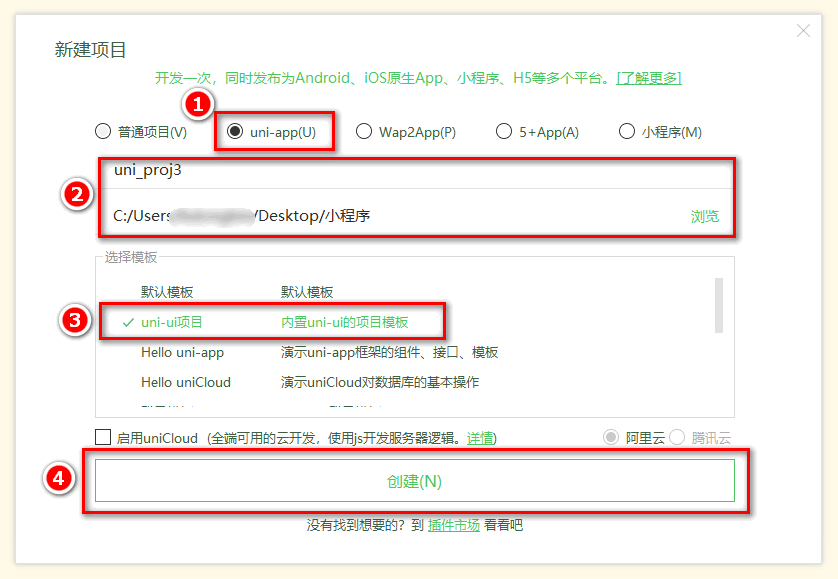


### 2. 目录分别负责什么

项目默认目录如下。后续操作都围绕这些位置展开：

```text
┌─components            uni-app组件目录
│  └─comp-a.vue         可复用的a组件
├─pages                 业务页面文件存放的目录
│  ├─index
│  │  └─index.vue       index页面
│  └─list
│     └─list.vue        list页面
├─static                存放应用引用静态资源（如图片、视频等）的目录，注意：静态资源只能存放于此
├─main.js               Vue初始化入口文件
├─App.vue               应用配置，用来配置小程序的全局样式、生命周期函数等
├─manifest.json         配置应用名称、appid、logo、版本等打包信息
└─pages.json            配置页面路径、页面窗口样式、tabBar、navigationBar 等页面类信息
```

`manifest.json` 管应用与平台打包信息，`pages.json` 管页面和导航配置，两者用途不同。应用引用的静态资源放在 `static`；复用界面放在 `components`；业务页面放在 `pages`。`main.js` 是 Vue 初始化入口，`App.vue` 放应用生命周期与全局样式。


## 三、运行到微信开发者工具

### 1. 填写 AppID

打开项目根目录的 `manifest.json`，进入“微信小程序配置”，填写**自己的微信小程序 AppID**。源码对应 `mp-weixin.appid`。

配套源码、课件中的 AppID 是教师的示例值，不直接沿用。

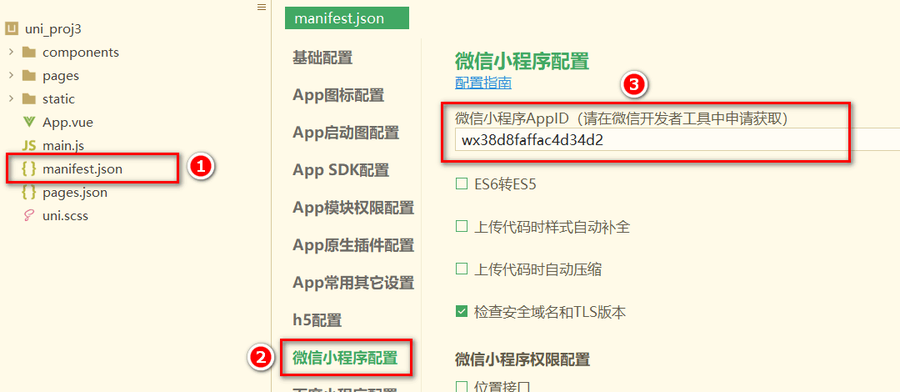


### 2. 配置开发者工具路径

在 HBuilderX 的“工具 → 设置 → 运行配置”中，填写本机**微信开发者工具的安装目录**。课件路径仅作示例，需指向自己实际安装的位置。

这一步让 HBuilderX 找到微信开发者工具，下一步还需要允许开发者工具接收启动指令。

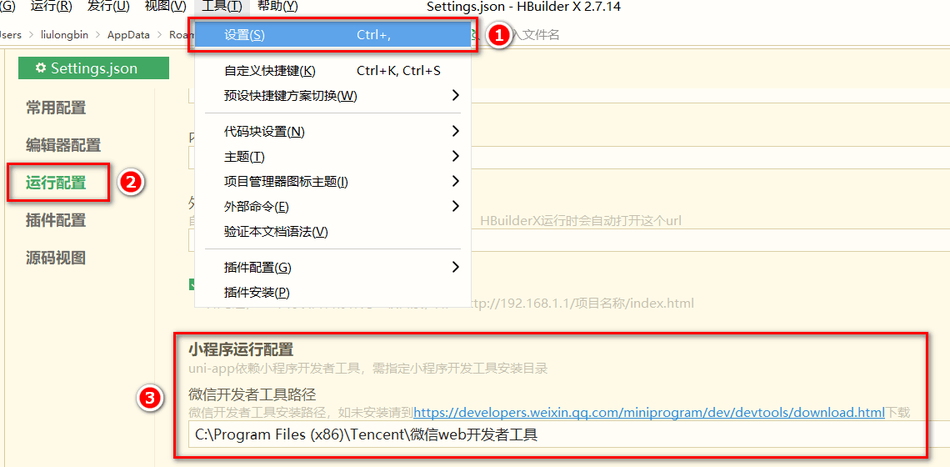


### 3. 开启服务端口并运行

在微信开发者工具中，通过“设置 → 安全设置”开启**服务端口**，使 HBuilderX 能启动并连接开发者工具。

返回 HBuilderX，选择“运行 → 运行到小程序模拟器 → 微信开发者工具”。编译成功后，开发者工具会打开当前项目，模拟器应显示默认首页。之后在 HBuilderX 修改并保存源文件，查看重新编译后的效果。

核对顺序：自己的 AppID → 开发者工具路径 → 服务端口 → HBuilderX 运行菜单。源码在 HBuilderX 项目中维护，编译产物在 `unpackage/dist` 下。

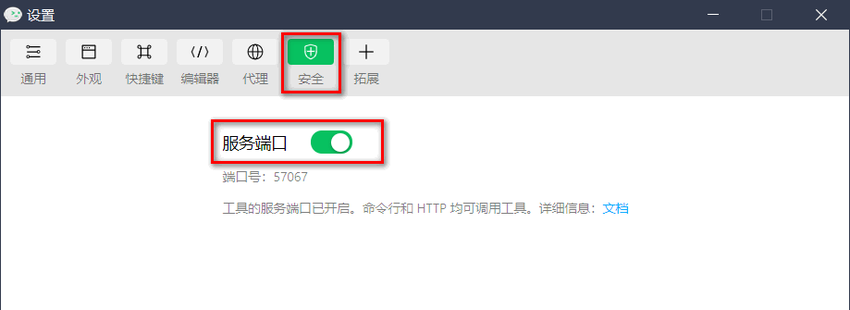


下面是课件中的运行菜单。先选择运行到微信开发者工具，编译成功后再查看模拟器；保存源码会触发重新编译。

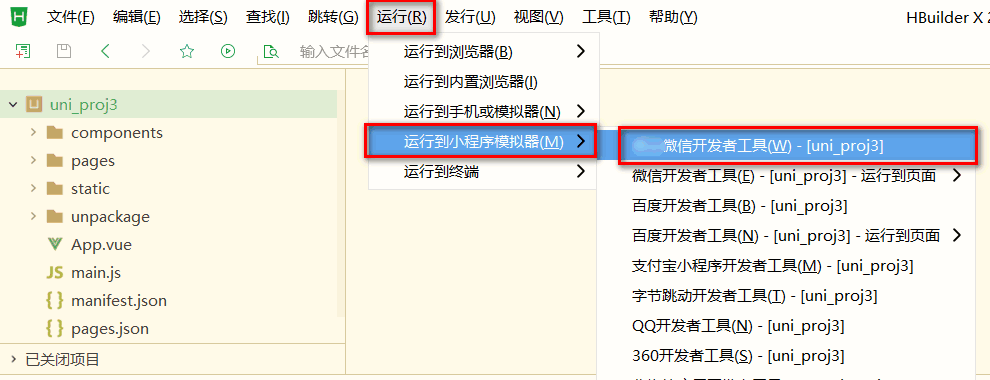


## 四、使用 Git 管理课程项目

### 1. 初始化与首次提交

在课程项目根目录新建 `.gitignore`：

```gitignore
# 忽略 node_modules 目录
/node_modules
/unpackage/dist
```

`node_modules` 是依赖安装结果，`unpackage/dist` 是编译产物，原课不把它们纳入版本管理。由于 Git 不跟踪空目录，可以在 `unpackage` 下创建 `.gitkeep` 占位，使该目录保留在仓库中。

切换到课程项目根目录，依次执行：

```bash
git init
git add .
git commit -m "init project"
```

至此，本地仓库保存了初始版本。下文的分支均以原课 `master` 为基线；如果自己的仓库默认分支名称不同，命令中的名称要与实际分支一致。


### 2. 托管到码云

原课远程托管顺序是：注册并激活码云账号 → 生成并配置 SSH 公钥 → 创建空白仓库 → 将本地项目上传到该仓库。

使用自己仓库页面提供的 SSH 地址配置远程仓库，推送后到码云核对文件。后续示例中的 `origin` 指这个已配置的远程仓库。资料仓库地址是课程来源，不能替换成自己的写入目标。


## 五、tabBar：创建四个主页面

### 1. 创建 tabbar 分支与页面

基于本地 `master` 创建功能分支：

```bash
git checkout -b tabbar
```

在 `pages` 目录上右键，选择“新建页面”，分别创建 `home`、`cate`、`cart`、`my`。勾选 SCSS 模板、“在 pages.json 中注册”和“创建同名目录”，页面会形成下面的路径。

| 页面 | 文件路径 | 作用 |
| --- | --- | --- |
| 首页 | `pages/home/home.vue` | 展示轮播、分类导航和楼层 |
| 分类 | `pages/cate/cate.vue` | 分类入口 |
| 购物车 | `pages/cart/cart.vue` | 购物车入口 |
| 我的 | `pages/my/my.vue` | 个人中心入口 |

这四个页面放在主包中，作为底部 tabBar 的切换目标。

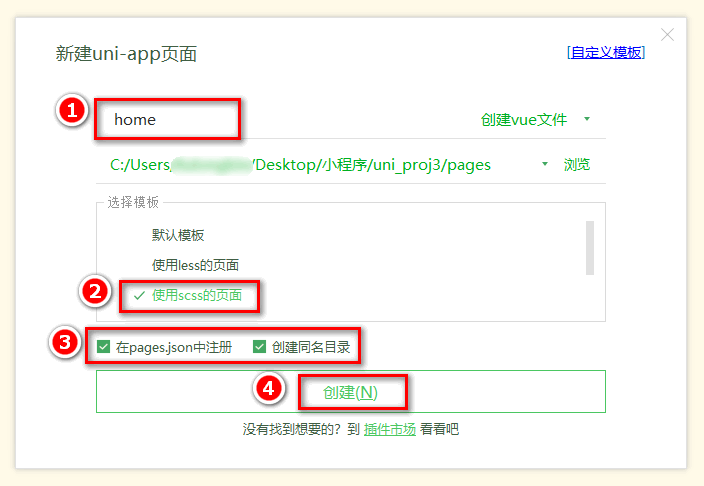


### 2. 配置图标、选中颜色与页面路径

将资料目录中的 `static` 拷贝到课程项目根目录，使用里面的 `tab_icons` 图标。在根目录的 `pages.json` 增加 `tabBar` 节点，和 `pages`、`globalStyle` 平级：

```json
{
  "tabBar": {
    "selectedColor": "#C00000",
    "list": [
      {
        "pagePath": "pages/home/home",
        "text": "首页",
        "iconPath": "static/tab_icons/home.png",
        "selectedIconPath": "static/tab_icons/home-active.png"
      },
      {
        "pagePath": "pages/cate/cate",
        "text": "分类",
        "iconPath": "static/tab_icons/cate.png",
        "selectedIconPath": "static/tab_icons/cate-active.png"
      },
      {
        "pagePath": "pages/cart/cart",
        "text": "购物车",
        "iconPath": "static/tab_icons/cart.png",
        "selectedIconPath": "static/tab_icons/cart-active.png"
      },
      {
        "pagePath": "pages/my/my",
        "text": "我的",
        "iconPath": "static/tab_icons/my.png",
        "selectedIconPath": "static/tab_icons/my-active.png"
      }
    ]
  }
}
```

`pagePath` 必须是已注册的页面路径，不带 `.vue` 扩展名；`iconPath` 与 `selectedIconPath` 分别提供未选中和选中的图标；`selectedColor` 控制选中项文字颜色。保存并运行后，应看到四个底部标签，点击各项能切换到对应页面。


### 3. 移除默认首页，统一顶部导航栏

原课接着清理模板内容：

1. 移除 HBuilderX 项目中的 `pages/index` 默认首页。
2. 同时移除 `pages.json` 的 `pages` 数组中对应的 `pages/index/index` 记录。
3. 原课为避免旧编译结果造成运行失败，在微信开发者工具中清理残留的默认 `pages/index` 目录。
4. 移除模板中不再需要的 `components/uni-link` 组件。

原讲义有一处写作 `page.json`，实际项目文件是 **`pages.json`**。清理后确保 `pages/home/home` 排在 `pages` 数组首位，让首页成为启动页面。

在同一个 `pages.json` 中修改 `globalStyle`：

```json
{
  "globalStyle": {
    "navigationBarTextStyle": "white",
    "navigationBarTitleText": "黑马优购",
    "navigationBarBackgroundColor": "#C00000",
    "backgroundColor": "#FFFFFF"
  }
}
```

预览时，顶部导航栏应显示白色文字“黑马优购”，背景为 `#C00000`，页面背景为白色。


### 4. 提交并合并 tabbar 分支

页面切换、图标与导航栏检查完成后，按原课顺序保存代码：

```bash
git add .
git commit -m "完成了 tabBar 的开发"
git push -u origin tabbar
git checkout master
git merge tabbar
git branch -d tabbar
```

先提交并推送功能分支，再切回 `master` 合并；最后删除已经合并的本地 `tabbar` 分支。`git push -u origin tabbar` 把功能分支保存到远程，并建立上游关系；`git merge tabbar` 更新本地 `master`，两者作用不同。


## 六、首页：配置网络请求

### 1. 创建 home 分支，安装请求包

完成 tabBar 并回到 `master` 后，创建首页功能分支：

```bash
git checkout -b home
```

原课指出，在小程序运行环境中不能直接沿用浏览器中的 axios，原生 `wx.request()` 又缺少拦截器等全局定制能力。因此选择 `@escook/request-miniprogram`，通过 Promise 写法配合 `async/await` 读取结果，并统一处理请求前后的提示。参考[请求包文档](https://www.npmjs.com/package/@escook/request-miniprogram)，在课程项目根目录安装：

```bash
npm install @escook/request-miniprogram
```

配套项目 `package.json` 的依赖为 `"@escook/request-miniprogram": "^0.2.1"`。本课沿用这一套调用方式。


### 2. 在 main.js 配置请求根路径与拦截器

保留原有 Vue 初始化代码，在项目根目录 `main.js` 中加入：

```javascript
import { $http } from '@escook/request-miniprogram'

uni.$http = $http
// 配置请求根路径
$http.baseUrl = 'https://www.uinav.com'

// 请求开始之前做一些事情
$http.beforeRequest = function (options) {
  uni.showLoading({
    title: '数据加载中...',
  })
}

// 请求完成之后做一些事情
$http.afterRequest = function () {
  uni.hideLoading()
}
```

`uni.$http = $http` 将请求对象挂到全局 `uni` 上，各页面可直接使用。后续传给 `.get()` 的是接口相对路径，会拼到 `baseUrl` 后。

请求开始时 `beforeRequest` 显示“数据加载中...”，请求完成时 `afterRequest` 关闭加载提示，因此页面无需重复写这一组逻辑。

> `https://www.uinav.com` 是原课根地址。本篇保留课程地址与接口路径便于对照；运行时如资料提供了替换地址，应只按对应接口文档调整根地址。本篇没有验证线上接口当前可用性。


### 3. 对照包内 API 文档

包内 API 文档说明，小程序请求使用 HTTPS。配套源码把根地址设为 `https://www.uinav.com`，以下三个首页接口均为 **GET 请求，无请求参数**：

| 首页模块 | 传给 `uni.$http.get()` 的路径 | 本天使用的数据字段 |
| --- | --- | --- |
| 轮播图 | `/api/public/v1/home/swiperdata` | `image_src`、`goods_id` |
| 分类导航 | `/api/public/v1/home/catitems` | `name`、`image_src` |
| 楼层 | `/api/public/v1/home/floordata` | `floor_title.image_src`、`product_list` |

响应正文的 `meta.status` 为 `200` 时表示业务成功，列表放在 `message` 中。文档特别标明新版返回值是 `res.data.message`，旧版 `res.data.data` 已废弃；所以下面用 `const { data: res }` 取出正文后，读取 `res.message`。

轮播响应里的 `goods_id` 用于打开详情页。分类响应里的 `name` 用于识别“分类”项。楼层的 `product_list` 每项有 `image_src`、`image_width`、`navigator_url`；后续布局和跳转分别使用这三个字段。接口给出的旧项目页面路径不能直接作为本项目的分包路径。


## 七、轮播图：获取数据与渲染

### 1. data → onLoad → methods

在 `pages/home/home.vue` 中：`data` 定义数组，`onLoad` 发起首次加载，`methods` 获取数据并更新数组。以下是先实现轮播图时的 `<script>` 内容：

```javascript
export default {
  data() {
    return {
      // 1. 轮播图的数据列表，默认为空数组
      swiperList: [],
    }
  },
  onLoad() {
    // 2. 在小程序页面刚加载的时候，调用获取轮播图数据的方法
    this.getSwiperList()
  },
  methods: {
    // 3. 获取轮播图数据的方法
    async getSwiperList() {
      // 3.1 发起请求
      const { data: res } = await uni.$http.get('/api/public/v1/home/swiperdata')
      // 3.2 请求失败
      if (res.meta.status !== 200) {
        return uni.showToast({
          title: '数据请求失败！',
          duration: 1500,
          icon: 'none',
        })
      }
      // 3.3 请求成功，为 data 中的数据赋值
      this.swiperList = res.message
    },
  },
}
```

`const { data: res }` 取出响应的 `data`，其中 `res.meta.status` 是接口业务状态，`200` 表示成功，`res.message` 是轮播列表。失败时 `return` 提示并终止赋值；成功时把列表赋给 `swiperList`，模板会响应更新。

后续增加分类导航和楼层时，在同一个 `data` 中继续加字段，在同一个 `onLoad` 中继续调用方法，不另写重复的 `export default`。


### 2. 渲染 swiper 并设置尺寸

在 `pages/home/home.vue` 的模板中加入轮播区域：

```html
<template>
  <view>
    <!-- 轮播图区域 -->
    <swiper :indicator-dots="true" :autoplay="true" :interval="3000" :duration="1000" :circular="true">
      <!-- 循环渲染轮播图的 item 项 -->
      <swiper-item v-for="(item, i) in swiperList" :key="i">
        <view class="swiper-item">
          <!-- 动态绑定图片的 src 属性 -->
          <image :src="item.image_src"></image>
        </view>
      </swiper-item>
    </swiper>
  </view>
</template>
```

| 属性或表达式 | 作用 |
| --- | --- |
| `:indicator-dots="true"` | 显示指示点 |
| `:autoplay="true"` | 自动播放 |
| `:interval="3000"` | 自动切换间隔 3000 毫秒 |
| `:duration="1000"` | 单次滑动动画时长 1000 毫秒 |
| `:circular="true"` | 循环衔接轮播 |
| `v-for="(item, i) in swiperList"` | 每条数据生成一个 `swiper-item` |
| `:src="item.image_src"` | 使用接口返回的图片地址 |

在 `<style lang="scss">` 中设置：

```scss
swiper {
 height: 330rpx;

 .swiper-item,
 image {
   width: 100%;
   height: 100%;
 }
}
```

轮播高 `330rpx`，内容和图片填满轮播区域。检查图片能正常显示、指示点与图片对应，并且会自动循环切换。


## 八、创建商品分包与封装提示

### 1. 配置 subpkg 分包

tabBar 的四个页面放主包，商品详情、商品列表等普通页面放分包，减少首次启动所需加载的内容。

1. 在项目根目录创建 `subpkg`。
2. 在 `pages.json` 中和 `pages` 平级的位置新增 `subPackages`。
3. 在 `subpkg` 下新建 `goods_detail` 页面，勾选注册与同名目录，选择分包 `subpkg`。

添加分包节点时的结构：

```json
{
  "pages": [
    {
      "path": "pages/home/home",
      "style": {}
    },
    {
      "path": "pages/cate/cate",
      "style": {}
    },
    {
      "path": "pages/cart/cart",
      "style": {}
    },
    {
      "path": "pages/my/my",
      "style": {}
    }
  ],
  "subPackages": [
    {
      "root": "subpkg",
      "pages": []
    }
  ]
}
```

新建并注册详情页后，分包内 `pages` 不再为空，记录为 `{"path": "goods_detail/goods_detail", "style": {}}`。配置里的分包页面路径相对于 `subpkg`，导航时使用完整路径 `/subpkg/goods_detail/goods_detail`。

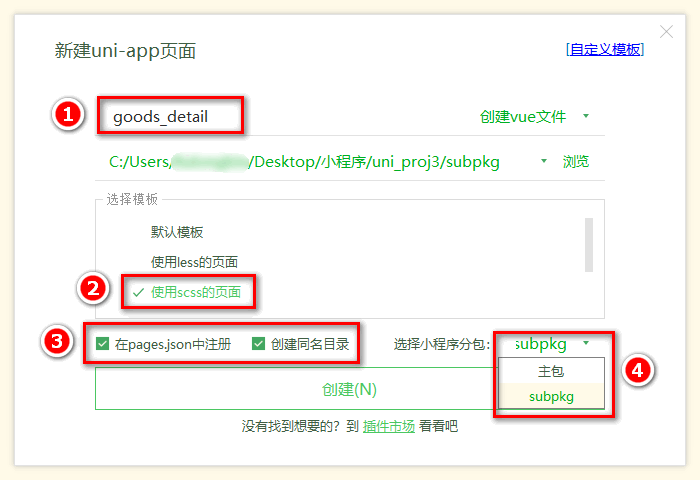


### 2. 点击轮播图打开详情页

把 `swiper-item` 内原来的 `view` 换为 `navigator`，保留 `swiper-item` 的遍历逻辑：

```html
<swiper-item v-for="(item, i) in swiperList" :key="i">
    <navigator class="swiper-item" :url="'/subpkg/goods_detail/goods_detail?goods_id=' + item.goods_id">
      <!-- 动态绑定图片的 src 属性 -->
      <image :src="item.image_src"></image>
    </navigator>
</swiper-item>
```

`url` 拼接商品详情路径和 `goods_id` 查询参数，传入的是当前轮播项的商品 ID。点击不同轮播图时，应打开对应的分包页面，并在页面路径中带上相应参数。

本天先建立跳转目标；详情内容尚未开发，打开空的详情页符合当前进度。


### 3. 封装 uni.$showMsg()

接口失败时会反复写 `uni.showToast()` 的相同选项。原课在 `main.js` 中给 `uni` 挂载一个提示方法：

```javascript
// 封装的展示消息提示的方法
uni.$showMsg = function (title = '数据加载失败！', duration = 1500) {
  uni.showToast({
    title,
    duration,
    icon: 'none',
  })
}
```

默认标题是“数据加载失败！”，时长 `1500` 毫秒，`icon: 'none'` 只显示文字。调用时可以传入自己的标题和时长。

接着把 `pages/home/home.vue` 的 `getSwiperList()` 替换为下面的简化方法，放在已有 `methods` 中：

```javascript
async getSwiperList() {
   const { data: res } = await uni.$http.get('/api/public/v1/home/swiperdata')
   if (res.meta.status !== 200) return uni.$showMsg()
   this.swiperList = res.message
}
```

配套源码默认标题写作“数据请求失败！”，与讲义的文字略有不同；方法参数、返回处理与提示方式一致。


## 九、分类导航：列表展示与 tabBar 切换

### 1. 请求分类导航数据

在 `pages/home/home.vue` 的 `data` 中新增 `navList: []`，在已有 `onLoad` 中调用 `this.getNavList()`。新增的方法放入 `methods`。

原课展示的导航模块逻辑如下，实际使用时合并进已有页面逻辑：

```javascript
export default {
  data() {
    return {
      // 1. 分类导航的数据列表
      navList: [],
    }
  },
  onLoad() {
    // 2. 在 onLoad 中调用获取数据的方法
    this.getNavList()
  },
  methods: {
    // 3. 在 methods 中定义获取数据的方法
    async getNavList() {
      const { data: res } = await uni.$http.get('/api/public/v1/home/catitems')
      if (res.meta.status !== 200) return uni.$showMsg()
      this.navList = res.message
    },
  },
}
```

接口为 `/api/public/v1/home/catitems`，成功后将 `res.message` 赋给 `navList`，失败仍统一调用 `uni.$showMsg()`。


### 2. 渲染导航图片并处理点击

在首页轮播区域后加入以下模板，直接使用最终带事件的结构：

```html
<!-- 分类导航区域 -->
<view class="nav-list">
  <view class="nav-item" v-for="(item, i) in navList" :key="i" @click="navClickHandler(item)">
    <image :src="item.image_src" class="nav-img"></image>
  </view>
</view>
```

在 `<style lang="scss">` 中加入：

```scss
.nav-list {
  display: flex;
  justify-content: space-around;
  margin: 15px 0;

  .nav-img {
    width: 128rpx;
    height: 140rpx;
  }
}
```

Flex 布局将导航项横向分布，图片尺寸为 `128rpx × 140rpx`，区域上下留 `15px`。图片地址来自各项的 `image_src`。


### 3. 点击“分类”切换到分类页

在 `methods` 中新增 `navClickHandler`：

```javascript
// nav-item 项被点击时候的事件处理函数
navClickHandler(item) {
  // 判断点击的是哪个 nav
  if (item.name === '分类') {
    uni.switchTab({
      url: '/pages/cate/cate'
    })
  }
}
```

事件传入当前 `item`，依据 `item.name === '分类'` 判断是否切换。因为目标 `pages/cate/cate` 属于 tabBar 页面，所以使用 `uni.switchTab()`。点击“分类”后，模拟器应显示分类页面，底部分类标签成为选中项。

本课只实现这一导航项的跳转，没有给其他导航项扩展额外页面。


## 十、楼层区域：标题、图片与商品列表跳转

### 1. 请求楼层数据

商城首页的“楼层”是按主题组织的商品图片区域。每个楼层包含标题 `floor_title` 与商品图片列表 `product_list`。

在 `pages/home/home.vue` 的 `data` 中新增 `floorList: []`，在已有 `onLoad` 中调用 `this.getFloorList()`；初始获取逻辑为：

```javascript
export default {
  data() {
    return {
      // 1. 楼层的数据列表
      floorList: [],
    }
  },
  onLoad() {
    // 2. 在 onLoad 中调用获取楼层数据的方法
    this.getFloorList()
  },
  methods: {
    // 3. 定义获取楼层列表数据的方法
    async getFloorList() {
      const { data: res } = await uni.$http.get('/api/public/v1/home/floordata')
      if (res.meta.status !== 200) return uni.$showMsg()
      this.floorList = res.message
    },
  },
}
```

接口为 `/api/public/v1/home/floordata`。`floorList` 保存所有楼层，模板外层先遍历楼层，再读取该楼层的商品图片。


### 2. 渲染楼层标题

在首页导航区域后新增楼层容器：

```html
<!-- 楼层区域 -->
<view class="floor-list">
  <!-- 楼层 item 项 -->
  <view class="floor-item" v-for="(item, i) in floorList" :key="i">
    <!-- 楼层标题 -->
    <image :src="item.floor_title.image_src" class="floor-title"></image>
  </view>
</view>
```

在 `<style lang="scss">` 中加入：

```scss
.floor-title {
  height: 60rpx;
  width: 100%;
  display: flex;
}
```

楼层标题读取 `item.floor_title.image_src`，宽度铺满容器，高度 `60rpx`。配套完成源码保留宽高两项，省略了讲义中的 `display: flex`，标题显示逻辑相同。


### 3. 一张大图与四张小图

在每个 `.floor-item` 中，楼层标题之后加入图片区域：

```html
<!-- 楼层图片区域 -->
<view class="floor-img-box">
  <!-- 左侧大图片的盒子 -->
  <view class="left-img-box">
    <image :src="item.product_list[0].image_src" :style="{width: item.product_list[0].image_width + 'rpx'}" mode="widthFix"></image>
  </view>
  <!-- 右侧 4 个小图片的盒子 -->
  <view class="right-img-box">
    <view class="right-img-item" v-for="(item2, i2) in item.product_list" :key="i2" v-if="i2 !== 0">
      <image :src="item2.image_src" mode="widthFix" :style="{width: item2.image_width + 'rpx'}"></image>
    </view>
  </view>
</view>
```

左侧固定使用 `product_list[0]`。右侧仍遍历 `product_list`，但用 `v-if="i2 !== 0"` 排除第一张，避免重复显示。原课返回的数据是左侧一张大图、右侧四张小图。

`image_width` 是图片设计宽度，绑定时加 `'rpx'`；`mode="widthFix"` 让高度按原图比例变化。因此无需分别硬编码每张图的高度。


在同一个 `<style lang="scss">` 中加入：

```scss
.right-img-box {
  display: flex;
  flex-wrap: wrap;
  justify-content: space-around;
}

.floor-img-box {
  display: flex;
  padding-left: 10rpx;
}
```

外层 `.floor-img-box` 使用 Flex 将大图和右侧容器并排；右侧容器 `flex-wrap: wrap` 使四张小图换行，`justify-content: space-around` 分配间距。对照数据与页面检查：左侧第一张图只出现一次，右侧剩余图片能排成两行，图片比例正确。


### 4. 创建商品列表页并转换 URL

在 `subpkg` 分包中创建 `goods_list` 页面，勾选 SCSS、同名目录和 `pages.json` 注册，选择 `subpkg` 分包。

接口给每张图片的原始跳转地址是 `navigator_url`，它的页面路径不是当前项目的分包路径。保留其中的查询参数，换成自己项目的商品列表地址。

将 `getFloorList()` 更新为：

```javascript
// 获取楼层列表数据
async getFloorList() {
  const { data: res } = await uni.$http.get('/api/public/v1/home/floordata')
  if (res.meta.status !== 200) return uni.$showMsg()

  // 通过双层 forEach 循环，处理 URL 地址
  res.message.forEach(floor => {
    floor.product_list.forEach(prod => {
      prod.url = '/subpkg/goods_list/goods_list?' + prod.navigator_url.split('?')[1]
    })
  })

  this.floorList = res.message
}
```

外层 `forEach` 处理每个楼层，内层处理楼层中的每张图；`split('?')[1]` 取出原地址问号后面的参数，给当前图片增加 `url` 字段。处理完再赋给 `floorList`，模板即可使用转换后的地址。这段代码按原课返回数据包含查询参数的结构编写。

例如，API 文档中“优质服饰”的原地址是 `/pages/goods_list?query=服饰`，转换后为 `/subpkg/goods_list/goods_list?query=服饰`。页面路径换成自己的分包路径，查询参数仍然保留。

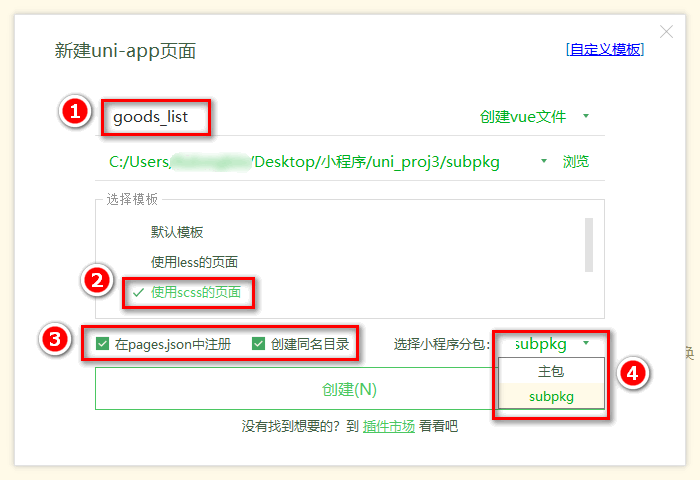


### 5. 把图片外层改为 navigator

用以下结构替换楼层中的 `.floor-img-box`。左侧外层与右侧每个图片项都改为 `navigator`，分别绑定刚增加的 `url`：

```html
<!-- 楼层图片区域 -->
<view class="floor-img-box">
  <!-- 左侧大图片的盒子 -->
  <navigator class="left-img-box" :url="item.product_list[0].url">
    <image :src="item.product_list[0].image_src" :style="{width: item.product_list[0].image_width + 'rpx'}" mode="widthFix"></image>
  </navigator>
  <!-- 右侧 4 个小图片的盒子 -->
  <view class="right-img-box">
    <navigator class="right-img-item" v-for="(item2, i2) in item.product_list" :key="i2" v-if="i2 !== 0" :url="item2.url">
      <image :src="item2.image_src" mode="widthFix" :style="{width: item2.image_width + 'rpx'}"></image>
    </navigator>
  </view>
</view>
```

两处 `navigator` 保留原来的布局类名，样式不需要重写。点击楼层图片应打开 `/subpkg/goods_list/goods_list` 并带上原接口的查询参数。

本天商品列表页仅有占位内容，尚未请求商品列表；检查的是页面与参数跳转是否正确。


## 十一、第 1 天完成版核对

### 1. 页面数据与启动时的调用

最终 `pages/home/home.vue` 的 `data` 和 `onLoad` 包含三个模块：

```javascript
export default {
  data() {
    return {
      swiperList: [],
      navList: [],
      floorList: []
    }
  },
  onLoad() {
    this.getSwiperList()
    this.getNavList()
    this.getFloorList()
  }
  // 三个请求方法和 navClickHandler 合并到同一个 methods 中
}
```

模板顺序为轮播 → 分类导航 → 楼层。网络请求使用同一个 `uni.$http`，请求失败使用同一个 `uni.$showMsg()`。


### 2. 核对最终页面与分包配置

下面是第 1 天完成版本的 `pages.json`，按原配置整理缩进。四个 tabBar 页面属于主包，商品详情与商品列表属于 `subpkg`：

```json
{
  "pages": [
    {
      "path": "pages/home/home",
      "style": {}
    },
    {
      "path": "pages/cate/cate",
      "style": {}
    },
    {
      "path": "pages/cart/cart",
      "style": {}
    },
    {
      "path": "pages/my/my",
      "style": {}
    }
  ],
  "subPackages": [
    {
      "root": "subpkg",
      "pages": [
        {
          "path": "goods_detail/goods_detail",
          "style": {}
        },
        {
          "path": "goods_list/goods_list",
          "style": {}
        }
      ]
    }
  ],
  "globalStyle": {
    "navigationBarTextStyle": "white",
    "navigationBarTitleText": "黑马优购",
    "navigationBarBackgroundColor": "#C00000",
    "backgroundColor": "#FFFFFF"
  },
  "tabBar": {
    "selectedColor": "#C00000",
    "list": [
      {
        "pagePath": "pages/home/home",
        "text": "首页",
        "iconPath": "static/tab_icons/home.png",
        "selectedIconPath": "static/tab_icons/home-active.png"
      },
      {
        "pagePath": "pages/cate/cate",
        "text": "分类",
        "iconPath": "static/tab_icons/cate.png",
        "selectedIconPath": "static/tab_icons/cate-active.png"
      },
      {
        "pagePath": "pages/cart/cart",
        "text": "购物车",
        "iconPath": "static/tab_icons/cart.png",
        "selectedIconPath": "static/tab_icons/cart-active.png"
      },
      {
        "pagePath": "pages/my/my",
        "text": "我的",
        "iconPath": "static/tab_icons/my.png",
        "selectedIconPath": "static/tab_icons/my-active.png"
      }
    ]
  }
}
```

`subPackages` 的大小写与根节点位置保持一致。分包内页面的 `path` 不再重复写 `subpkg/`；只有实际导航 URL 使用根目录开始的完整路径。


### 3. main.js 完成版源码

下方是项目第 1 天包内的 `代码/uni-shop-2/main.js`。网络请求和提示方法配置在 Vue 应用挂载前，原有 Vue 初始化代码保留：

```javascript
import Vue from 'vue'
import App from './App'

// 导入网络请求的包
import { $http } from '@escook/request-miniprogram'

uni.$http = $http

// 请求的根路径
$http.baseUrl = 'https://www.uinav.com'

// 请求拦截器
$http.beforeRequest = function(options) {
  uni.showLoading({
    title: '数据加载中...'
  })
}

// 响应拦截器
$http.afterRequest = function() {
  uni.hideLoading()
}

// 封装弹框的方法
uni.$showMsg = function(title = '数据请求失败！', duration = 1500) {
  uni.showToast({
    title,
    duration,
    icon: 'none'
  })
}

Vue.config.productionTip = false

App.mpType = 'app'

const app = new Vue({
  ...App
})
app.$mount()
```

此处提示默认文字按配套源码保留为“数据请求失败！”，前文步骤则保留讲义中的“数据加载失败！”。二者的调用方式相同。


### 4. 首页完成版源码

下方保留项目第 1 天包内 `代码/uni-shop-2/pages/home/home.vue` 的原始内容，便于对照零散步骤合并后的结果：

```vue
<template>
  <view>
    <!-- 轮播图的区域 -->
    <swiper :indicator-dots="true" :autoplay="true" :interval="3000" :duration="1000" :circular="true">
      <swiper-item v-for="(item, i) in swiperList" :key="i">
        <navigator class="swiper-item" :url="'/subpkg/goods_detail/goods_detail?goods_id=' + item.goods_id">
          <image :src="item.image_src"></image>
        </navigator>
      </swiper-item>
    </swiper>

    <!-- 分类导航区域 -->
    <view class="nav-list">
      <view class="nav-item" v-for="(item, i) in navList" :key="i" @click="navClickHandler(item)">
        <image :src="item.image_src" class="nav-img"></image>
      </view>
    </view>

    <!-- 楼层区域 -->
    <!-- 楼层的容器 -->
    <view class="floor-list">
      <!-- 每一个楼层的 item 项 -->
      <view class="floor-item" v-for="(item, i) in floorList" :key="i">
        <!-- 楼层的标题 -->
        <image :src="item.floor_title.image_src" class="floor-title"></image>
        <!-- 楼层的图片区域 -->
        <view class="floor-img-box">
          <!-- 左侧大图片的盒子 -->
          <navigator class="left-img-box" :url="item.product_list[0].url">
            <image :src="item.product_list[0].image_src" :style="{width: item.product_list[0].image_width + 'rpx'}" mode="widthFix"></image>
          </navigator>
          <!-- 右侧 4 个小图片的盒子 -->
          <view class="right-img-box">
            <navigator class="right-img-item" v-for="(item2, i2) in item.product_list" :key="i2" v-if="i2 !== 0" :url="item2.url">
              <image :src="item2.image_src" :style="{width: item2.image_width + 'rpx'}" mode="widthFix"></image>
            </navigator>
          </view>
        </view>
      </view>
    </view>
  </view>
</template>

<script>
  export default {
    data() {
      return {
        // 这是轮播图的数据列表
        swiperList: [],
        // 分类导航的数据列表
        navList: [],
        // 楼层的数据
        floorList: []
      };
    },
    onLoad() {
      // 调用方法，获取轮播图的数据
      this.getSwiperList()
      this.getNavList()
      this.getFloorList()
    },
    methods: {
      async getSwiperList() {
        const { data: res } = await uni.$http.get('/api/public/v1/home/swiperdata')
        // 请求失败
        if (res.meta.status !== 200) return uni.$showMsg()

        this.swiperList = res.message
      },
      async getNavList() {
        const { data: res } = await uni.$http.get('/api/public/v1/home/catitems')
        if (res.meta.status !== 200) return uni.$showMsg()
        this.navList = res.message
      },
      navClickHandler(item) {
        if (item.name === '分类') {
          uni.switchTab({
            url: '/pages/cate/cate'
          })
        }
      },
      // 获取首页楼层数据的方法
      async getFloorList() {
        const { data: res } = await uni.$http.get('/api/public/v1/home/floordata')
        if (res.meta.status !== 200) return uni.$showMsg()

        // 对数据进行处理
        res.message.forEach(floor => {
          floor.product_list.forEach(prod => {
            prod.url = '/subpkg/goods_list/goods_list?' + prod.navigator_url.split('?')[1]
          })
        })
        this.floorList = res.message
      }
    }
  }
</script>

<style lang="scss">
  swiper {
    height: 330rpx;

    .swiper-item,
    image {
      width: 100%;
      height: 100%;
    }
  }

  .nav-list {
    display: flex;
    justify-content: space-around;
    margin: 15px 0;

    .nav-img {
      width: 128rpx;
      height: 140rpx;
    }
  }

  .floor-title {
    width: 100%;
    height: 60rpx;
  }

  .right-img-box {
    display: flex;
    flex-wrap: wrap;
    justify-content: space-around;
  }

  .floor-img-box {
    display: flex;
    padding-left: 10rpx;
  }
</style>
```


### 5. 提交 home 分支

页面与跳转核对完成后，按原课顺序提交、推送并合并：

```bash
git add .
git commit -m "完成了 home 首页的开发"
git push -u origin home
git checkout master
git merge home
git branch -d home
```

这些是课程项目的版本管理步骤，本篇没有在当前笔记仓库执行提交、分支切换或推送。


### 6. 本天验证点与完成范围

| 操作 | 应看到的效果 |
| --- | --- |
| HBuilderX 运行到微信开发者工具 | 编译成功，工具打开项目，默认进入首页 |
| 切换四个底部标签 | 页面与选中图标、文字颜色一致 |
| 加载首页 | 轮播、分类导航、楼层分别展示接口数据 |
| 点击轮播图片 | 打开详情分包页，携带 `goods_id` |
| 点击首页“分类”导航项 | 切换到 tabBar 分类页 |
| 点击任一楼层图片 | 打开列表分包页，保留原地址查询参数 |

本天完成开发环境、主包导航、首页数据展示，以及详情页和列表页的跳转入口。分类内容、搜索、商品列表与详情内容属于后续课程，本篇不提前实现。

笔记已核对 JSON、代码围栏、静态 JavaScript 语法、图片附件以及源码里的页面和图标路径；没有在微信开发者工具中实际运行项目，上表是跟课时应检查的效果。
